# Chuẩn bị dữ liệu MNIST

Nguồn: [MNIST được dẫn trong đề](https://github.com/cvdfoundation/mnist).

Dùng 60.000 ảnh train và 10.000 ảnh test chuẩn, mỗi ảnh có kích thước 28 × 28. Không chia lại train/test.

## 1. Cài thư viện

In [1]:
%pip install numpy pandas matplotlib "scikit-learn>=1.8" joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Tải dữ liệu

In [2]:
from pathlib import Path
from urllib.request import urlopen
import gzip
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if (ROOT / 'Lab2_du_lieu_MNIST').is_dir():
    ROOT = ROOT / 'Lab2_du_lieu_MNIST'

raw = ROOT / 'data' / 'raw'
raw.mkdir(parents=True, exist_ok=True)
url = 'https://storage.googleapis.com/cvdf-datasets/mnist/'
files = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
         't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']

for name in files:
    path = raw / name
    if not path.exists():
        with urlopen(url + name, timeout=60) as response:
            path.write_bytes(response.read())
    print(name, path.stat().st_size, 'bytes')

train-images-idx3-ubyte.gz 9912422 bytes
train-labels-idx1-ubyte.gz 28881 bytes
t10k-images-idx3-ubyte.gz 1648877 bytes
t10k-labels-idx1-ubyte.gz 4542 bytes


## 3. Đọc ảnh và nhãn

In [3]:
with gzip.open(raw / files[0], 'rb') as f:
    X_train = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(60000, 784)
with gzip.open(raw / files[1], 'rb') as f:
    y_train = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
with gzip.open(raw / files[2], 'rb') as f:
    X_test = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(10000, 784)
with gzip.open(raw / files[3], 'rb') as f:
    y_test = np.frombuffer(f.read(), dtype=np.uint8, offset=8)

np.savez_compressed(ROOT / 'data' / 'mnist.npz', X_train=X_train, y_train=y_train,
                    X_test=X_test, y_test=y_test)
print('Train:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)
print('Train theo lớp:', np.bincount(y_train))
print('Test theo lớp:', np.bincount(y_test))

Train: (60000, 784) (60000,)
Test: (10000, 784) (10000,)
Train theo lớp: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Test theo lớp: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


## 4. Xem ảnh mẫu

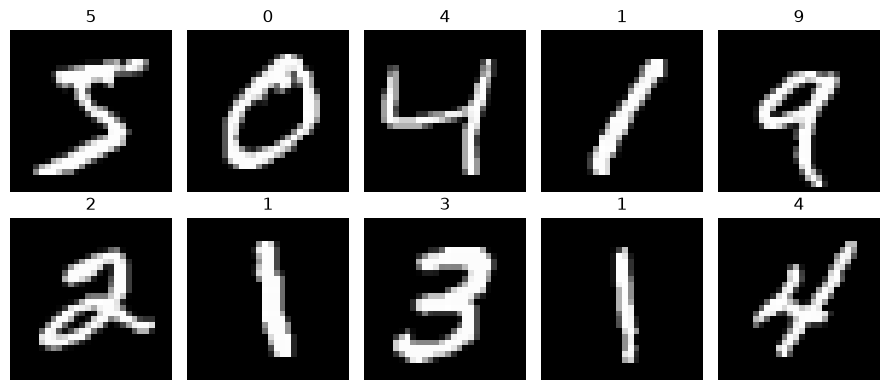

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train[i]))
    ax.axis('off')
plt.tight_layout()
plt.savefig(ROOT / 'data' / 'sample_images.png', dpi=150)
plt.show()

## 5. Lưu thông tin nguồn

In [5]:
source = {'source': 'https://github.com/cvdfoundation/mnist',
          'download_url': url, 'train_samples': len(y_train), 'test_samples': len(y_test),
          'image_shape': [28, 28], 'normalization': 'pixel / 255.0', 'sha256': {}}
for name in files:
    source['sha256'][name] = hashlib.sha256((raw / name).read_bytes()).hexdigest()
(ROOT / 'data' / 'source.json').write_text(json.dumps(source, indent=2), encoding='utf-8')
print('Dữ liệu đã lưu tại:', ROOT / 'data')

Dữ liệu đã lưu tại: d:\Tài liệu học tập\Học máy thống kê\Thực hành\Lab2_du_lieu_MNIST\data
